<a href="https://colab.research.google.com/github/lorenzo-fattori/dtm-dcai/blob/main/slides/lab-04-fairness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "Fairness"
bibliography:
  - refs/refs.bib
---


# Session plan: theory and coding

| Activity |
| --- |
| Theory 1: Bias, equal opportunity, Adult data, and group audits |
| [Coding 1 (~15 min): Exercises 1-2](#coding-break-1) |
| Theory 2: Intersectional audit, governance, and pre-/in-processing for equal opportunity |
| [Coding 2 (~15 min): Exercises 3-4](#coding-break-2) |
| Theory 3: Post-processing for equal opportunity, fairness and performance Pareto comparisons, and remediation |
| [Coding 3 (~15 min): Exercises 5-6](#coding-break-3) |


# Are we giving everyone the same (or, at least, comparable) treatment?

::::{.columns}
:::{.column width="33%"}
![Equality](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/fairness/equality.png?raw=1)
:::
:::{.column width="33%"}
:::{.fragment}
![Equity](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/fairness/equity.png?raw=1)
:::
:::
:::{.column width="33%"}
:::{.fragment}
![Justice](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/fairness/justice.png?raw=1)
:::
:::
::::

# [Amazon scraps secret AI recruiting tool that showed bias against women](https://www.reuters.com/article/world/insight-amazon-scraps-secret-ai-recruiting-tool-that-showed-bias-against-women-idUSKCN1MK0AG/): When Past CVs Become a Hiring Standard

> By 2015, it was clear that the system was not rating candidates in a gender-neutral way because it was built on data accumulated from CVs submitted to the firm mostly from males, Reuters claimed.

- **Task:** an experimental tool scored candidates' CVs to support recruiting.
- **What happened:** The model favored male applicants. It penalized the term "women's" and graduates of two women's colleges.
- **Data-centric lesson:** historical applicant data can encode exclusion, training CVs from a ten-year period were mostly from men.

# Inequality Can Be in the Label

![Before changing the model, ask whether the target contains inequality the model will learn to reproduce.](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/fairness/inequality.png?raw=1){fig-alt="Inequality illustration showing unequal starting positions." width="55%"}

In CV screening, a model trained on historical shortlisting decisions may reproduce past exclusion.

- **Discuss:** would removing names and gendered words be enough? What evidence would show that a CV score measures job-relevant ability?

# Toy Example

- $X=\{X_0, X_1, X_2, \ldots\}$ is the set of input features (e.g., education, experience).
- $A$ is a sensitive group membership, shown as two shapes (e.g., gender).
- Ground truth: $Y=1$ means qualified for the job under a job-relevant assessment.
- Model predictions: $\hat{Y}=1$ means shortlisted for interview; $\hat{Y}=0$ means not shortlisted.

![A model can look accurate overall while one group lives in a different part of the feature space.](https://github.com/w4bo/AA2627-unibo-dcai/blob/main/slides/img/fairness/A_dist.svg?raw=1)

One group has a shifted score distribution because of external conditions such as unequal access to training or work experience.

- Even a "shape-blind" model may infer group membership from correlated features.
- Omitting $A$ does not remove its influence.


# Gender Shades

**Gender Shades (2018):** audit of three commercial systems that .

> Automated systems are not inherently neutral. They reflect the priorities, preferences, and prejudices-the coded gaze-of those who have the power to mold artificial intelligence. [Gender shades](https://www.media.mit.edu/projects/gender-shades/overview/) and [Gender shades project](http://gendershades.org/overview.html)

- **Task:** classified gender from faces [@buolamwini2018gender].
- **What happened:** Error rates reached **34.7% for darker-skinned females**, compared with a maximum of **0.8% for lighter-skinned males**.
- **Data-centric lesson:** audit intersections of group attributes ([Gender Shades paper](https://proceedings.mlr.press/v81/buolamwini18a.html)).

:::{.fragment}
**Discuss:** should medical and loan requests use the same representation policy?
:::

# Why Different Treatment Happens

Different treatment usually does not require a programmer to intentionally encode racism or sexism.

:::{.fragment}
**But**, the job of a ML algorithm is to learn discriminatory patterns *from the data* (e.g., how can I distinguish two classes?).

*Problems*? Think about *what is the system trying to do, who is affected, and what should be checked before deployment?*
:::

:::{.fragment}
- the training set is not representative of the deployment population,
- absence of data reflects historical exclusion,
- small subgroup sample sizes do not generalize well,
- labels encode previous biased decisions,
- features include proxies for protected attributes,
- and data quality differs across groups.
:::

# What Bias Is

> A machine-learning system is biased when its data, modeling process, or deployment context creates systematically different errors, opportunities, or harms for different groups.

- **Data collection bias**: who appears in the data, who is missing, and under what conditions measurements are made.
- **Algorithmic process bias**: how features, objectives, thresholds, and validation metrics encode priorities.
- **Deployment bias**: how predictions are interpreted and used by humans or institutions.


# What Bias Is Not

- Bias is **not necessarily malicious**. It can arise even when everyone involved has good intentions.
- Bias is **not one and done**. A model may become unfair as populations, pipelines, policies, or deployment settings change.
- Bias is **not new**. Researchers and practitioners have discussed discrimination, fairness, and measurement harms for decades.

# From Headlines to a Fairness Audit

We now formalize these questions:

- **Data and proxies:** who appears in the dataset, and which features encode group membership?
- **Targets:** does the observed label measure the outcome we actually want?
- **Evaluation:** which groups and intersections need separate metrics, and which errors matter most?
- **Interventions:** does a proposed fix improve the intended behavior across realistic contexts?


# What Is a Predicted Probability?

A **predicted probability** $\hat{P}(Y=1\mid X)$ is the model's estimate of how likely the positive outcome is, based on observed features $X$.

- In fairness literature, this is also called a **risk score** [@kleinberg2017inherent].

**Working example**: CV shortlisting

- $Y=1$ means qualified for the job.
- *Decision threshold:* shortlist the applicant (i.e., $\hat{Y}=1$) if $\hat{P}(Y=1\mid X)\geq thr$; otherwise do not shortlist (i.e., $\hat{Y}=0$).
    - A larger $\hat{P}(Y=1\mid X)$ means a higher predicted probability that the applicant is qualified



# Quantitative Fairness Definitions

| Definition | Core idea | Formula |
|---|---|---|
| Fairness through unawareness | Do not use $A$ directly | |
| Statistical parity | Equal positive prediction rates | $P(\hat{Y}=1\mid A=a)=P(\hat{Y}=1\mid A=b)$ |
| Equal opportunity (TPR parity) | Equal true positive rates | $P(\hat{Y}=1\mid Y=1,A=a)=P(\hat{Y}=1\mid Y=1,A=b)$ |
| Equalized odds (error-rate balance) | Equal true positive and false positive rates | $P(\hat{Y}=1\mid Y=y,A=a)=P(\hat{Y}=1\mid Y=y,A=b),\quad y\in\{0,1\}$ |
| Individual fairness | Similar people receive similar prediction distributions | $D\!\left(\hat{P}(\cdot\mid x),\hat{P}(\cdot\mid x')\right)\leq d(x,x')$ |

$D$ measures distance between prediction distributions; $d$ is a task-relevant distance between people.


# Calibration: Do Predicted Probabilities Match Observed Outcomes? {visibility="hidden"}

A model is **calibrated** when, at every predicted probability level, the fraction of positive outcomes ($Y = 1$) among the groups assigned that probability matches the predicted value.

- For example, among 100 CV applicants assigned $\hat{P}(Y=1\mid X)=0.7$, approximately 70 should be qualified under a job-relevant assessment.

**Calibration within groups** requires this agreement separately in every group.

For applicants all assigned a probability of 0.7:

| Group | Applicants | Qualified for the job | Observed fraction |
|---|---:|---:|---:|
| A | 10 | 9 | 90% |
| B | 10 | 5 | 50% |
| Overall | 20 | 14 | 70% |

The overall fraction matches 70%, but the group fractions do not: predictions underestimate the observed rate in A and overestimate it in B.

- This illustrates agreement overall at one probability level, not calibration across all levels.
- Observed fractions vary with sampling; 10 people per group may be too few to draw a firm conclusion about calibration.
Calibration within groups: $P(Y=1\mid \hat{P}=p,A=a)=p$, where $\hat{P}$ is the predicted probability.


# Statistical parity and equal opportunity

**Statistical parity** asks for equal positive prediction rates: $P(\hat{Y} = 1 \mid A = a) = P(\hat{Y} = 1 \mid A = b)$

**Equal opportunity** asks for equal true positive rates:  $P(\hat{Y} = 1 \mid Y = 1, A = a) = P(\hat{Y} = 1 \mid Y = 1, A = b)$

- Useful when missing qualified or truly positive cases is the central harm.

> CV screening example: $\hat{Y}=1$ means shortlisted for interview; $Y=1$ means qualified for job position; $A=gender$.
>
> - *Statistical parity:* shortlist 40 of 200 women and 20 of 100 men: both selection rates are **20%**, regardless of qualification.
> - *Equal opportunity:* if 40 women and 60 men are qualified, shortlist 30 qualified women and 45 qualified men: both true positive rates are **75%**.
>     - The denominator is qualified applicants, *not all* applicants.

# When Fairness Criteria Conflict

Each group has 100 CV applicants: 60 qualified applicants ($Y=1$) in A and 30 in B.

- Circles $Y=1$ and crosses $Y=0$; orange rings mark shortlisted people ($\hat{Y}=1$).

- **Statistical parity:** shortlist 40 applicants in each group. B has only 30 qualified applicants, so at least 10 shortlisted people in B must be unqualified.
- **Equal opportunity:** shortlist 80% of qualified applicants in each group (48 in A, 24 in B); the overall shortlisting rates differ.

:::{.notes}
The unqualified selections above are forced by the 40% selection target and B's limited number of qualified applicants, not by statistical parity alone. A common selection rate of at most 30% could avoid unqualified selections in this example. We assume qualification is known and qualified applicants are shortlisted first to make the trade-off explicit.

Suppose groups have different positive-class rates $p_a=P(Y=1\mid A=a)$.

- **Equalized odds** requires the same true positive rate (TPR) and false positive rate (FPR) in each group.
- With shared TPR and FPR, the positive prediction rate in group $a$ is:

$$q_a=\mathrm{TPR}\,p_a+\mathrm{FPR}\,(1-p_a).$$

- If $\mathrm{TPR}\ne\mathrm{FPR}$, different $p_a$ values imply different $q_a$ values.
    - Equalized odds then conflicts with **demographic parity**, which requires equal $q_a$ values.
- Both criteria can hold when base rates are equal or when $\mathrm{TPR}=\mathrm{FPR}$.
    - The latter means predictions do not distinguish positives from negatives within a group.
:::


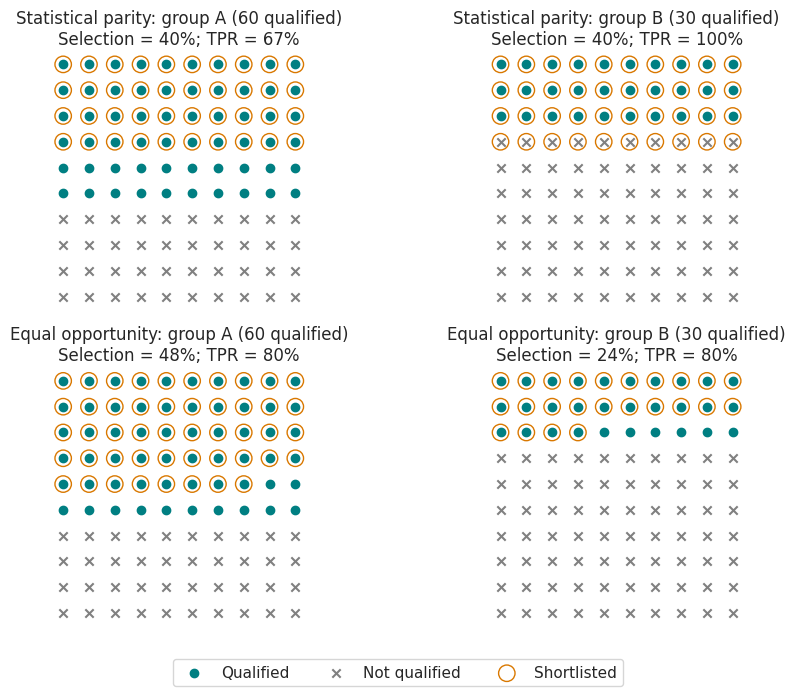

In [165]:
#| echo: false
#| fig-width: 10
#| fig-height: 7
import numpy as np
import matplotlib.pyplot as plt

# Shortlist qualified applicants first in this illustrative example.
# Each pair gives (qualified, not qualified) applicants shortlisted in groups A and B.
policies = {"Statistical parity": [(40, 0), (30, 10)],
            "Equal opportunity": [(48, 0), (24, 0)]}
positions = np.arange(100)
x, y = positions % 10, 9 - positions // 10  # Arrange 100 people in a grid.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (policy, counts) in enumerate(policies.items()):
    for column, (group, positives) in enumerate(zip(["A", "B"], [60, 30])):
        ax = axes[row, column]
        positive = positions < positives
        qualified_selected, unqualified_selected = counts[column]
        selected = ((positive & (positions < qualified_selected))
                    | (~positive & (positions < positives + unqualified_selected)))
        ax.scatter(x[positive], y[positive], color="#007F82", label="Qualified")
        ax.scatter(x[~positive], y[~positive], color="grey", marker="x", label="Not qualified")
        ax.scatter(x[selected], y[selected], s=140, facecolors="none",
                   edgecolors="#D97800", label="Shortlisted")
        recall = (selected & positive).sum() / positives
        ax.set_title(f"{policy}: group {group} ({positives} qualified)\n"
                     f"Selection = {selected.mean():.0%}; TPR = {recall:.0%}")
        ax.set_aspect("equal")
        ax.set_axis_off()
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()


# What Is [Fairlearn](https://fairlearn.org/)?

**Fairlearn** is an open-source Python toolkit for assessing and mitigating fairness issues in machine learning systems [@bird2020fairlearn].

We start with **auditing**: `MetricFrame` organizes metrics overall and by group, much as a pandas `DataFrame` organizes tabular data.

- Compare selection rates, TPR, and FPR across groups.
- Summarize the largest group differences.
- An audit measures disparities; it does not change the model.

:::{.fragment}
For the CV example, `y_test` records qualification, `y_pred` records shortlisting, and `A_test` records group membership.

```python
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate
mf = MetricFrame(
    metrics={"shortlist_rate": selection_rate, "qualified_recall": true_positive_rate},
    y_true=y_test, y_pred=y_pred, sensitive_features=A_test,
)
mf.overall       # metrics over all applicants
mf.by_group      # the same metrics separately for each group
mf.difference()  # largest minus smallest group value, per metric
```

- The gap in `shortlist_rate` measures departure from statistical parity.
- The gap in `qualified_recall` measures departure from equal opportunity.
- `MetricFrame` assesses predictions; mitigation requires a separate transformer or estimator.

Source: [MetricFrame API](https://fairlearn.org/v0.11/api_reference/generated/fairlearn.metrics.MetricFrame.html).
:::

In [166]:
#| echo: false
import importlib.util
import subprocess
import sys

packages = {"fairlearn": "fairlearn", "sklearn": "scikit-learn", "pandas": "pandas",
            "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:  # Install only missing packages.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [167]:
#| echo: false
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # Reuse the same seed for reproducible examples.


In [168]:
#| echo: false
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [169]:
#| echo: false
from fairlearn.metrics import (
    MetricFrame, selection_rate, true_positive_rate,
    false_positive_rate, false_negative_rate,
)
from fairlearn.preprocessing import CorrelationRemover
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.reductions import ExponentiatedGradient, TruePositiveRateParity


In [170]:
#| echo: false
def describe_by_group(df, group, target):
    summary = df.groupby(group)[target].agg(count="size", positive_rate="mean")
    summary["share"] = summary["count"] / summary["count"].sum()
    return summary[["count", "share", "positive_rate"]].sort_values("count", ascending=False)

def load_cached_csv(url, filename, **options):
    path = Path(".cache/datasets") / filename
    if not path.exists():  # Download once; reuse the local copy on later runs.
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


In [171]:
#| echo: false
def make_tabular_pipeline(X, depth=5):
    numeric = X.select_dtypes(include="number").columns
    categorical = X.columns.difference(numeric, sort=False)
    preprocessor = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore", min_frequency=20),
        ), categorical),  # Convert categories into numeric indicator columns.
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)),
    ])


# Part I. How do we *identify* fairness issues?

# Adult Income Dataset

The Adult dataset is census-derived tabular data. The task is to predict whether annual income exceeds 50K USD.

In [172]:
adult_df = load_cached_csv(
    "https://archive.ics.uci.edu/static/public/2/data.csv", "adult.csv",
    na_values="?", skipinitialspace=True,  # The dataset uses ? for missing values.
)
y_adult = adult_df.pop("income").str.rstrip(".").eq(">50K").astype(int)
X_adult_raw = adult_df.copy()  # Keep predictors separate from the income label.
adult_df["income_gt_50k"] = y_adult
adult_df.head()


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income_gt_50k
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


# Forget about fairness for a moment: how well can we predict income?

In [173]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_adult_raw, y_adult, test_size=0.30, random_state=RANDOM_STATE,
    stratify=y_adult,  # Preserve the positive/negative label proportions.
)
X_train, X_test = X_train_raw, X_test_raw
baseline = make_tabular_pipeline(X_train, depth=4)
baseline


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 min_frequency=20))]),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object'))])),
                ('model',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])

# Forget about fairness for a moment: how well can we predict income?

In [174]:
baseline.fit(X_train, y_train)
y_pred_raw = baseline.predict(X_test)  # Save the original model's predictions.
y_accuracy = balanced_accuracy_score(y_test, y_pred_raw)
print("Balanced accuracy:", round(y_accuracy, 3))


Balanced accuracy: 0.741


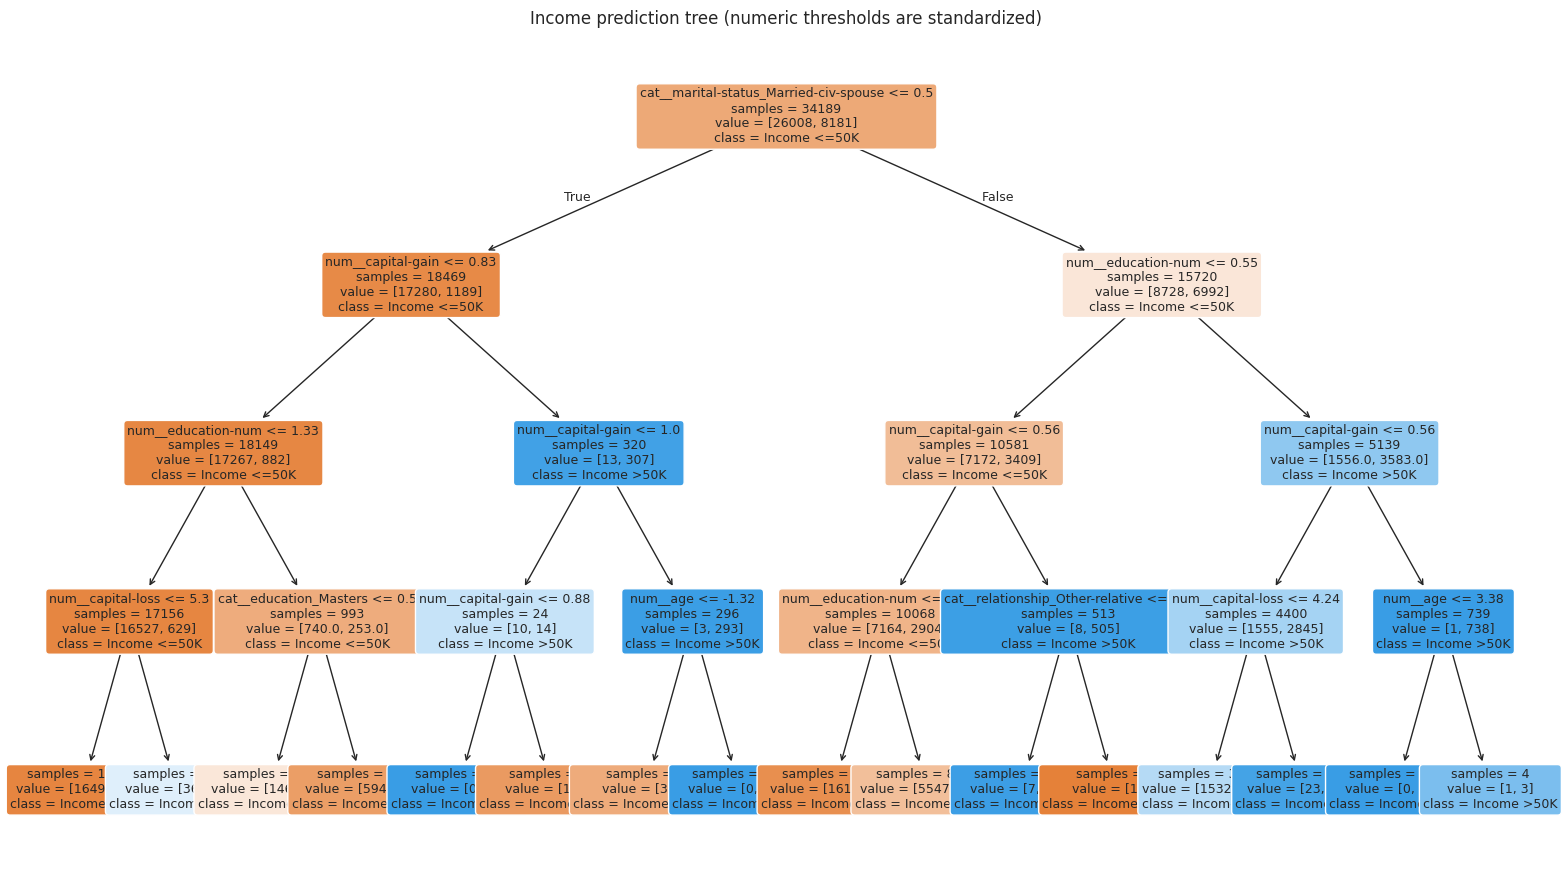

In [175]:
#| echo: false
#| fig-width: 16
#| fig-height: 9
fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(
    baseline["model"], feature_names=baseline["preprocess"].get_feature_names_out(),
    class_names=["Income <=50K", "Income >50K"], filled=True, rounded=True,
    impurity=False, precision=2, fontsize=9, ax=ax,
)
ax.set_title("Income prediction tree (numeric thresholds are standardized)")
plt.tight_layout()
plt.show()


# Which features does the income prediction tree use?


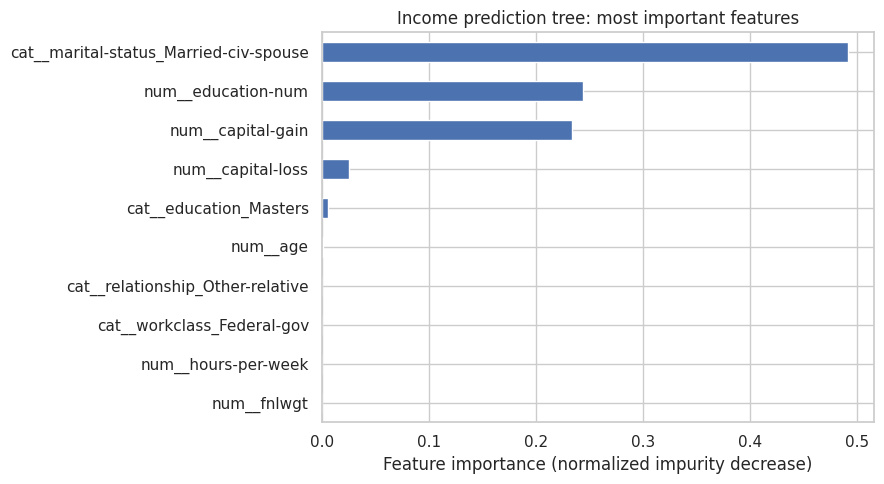

In [176]:
#| echo: false
importance = pd.Series(
    baseline["model"].feature_importances_,
    index=baseline["preprocess"].get_feature_names_out(),
)
# Inspect the ten most important encoded features used by this tree.
top_features = importance.nlargest(10).sort_values()
top_features.plot.barh(figsize=(9, 5))
plt.xlabel("Feature importance (normalized impurity decrease)")
plt.title("Income prediction tree: most important features")
plt.tight_layout()
plt.show()


# Data-Centric Audit Questions: Which features might act as proxies for protected attributes?

In [177]:
#| echo: false
def bin_if_numeric(values):
    if pd.api.types.is_numeric_dtype(values):
        cuts = values.dropna().quantile(np.arange(0.1, 1, 0.1)).unique()
        values = pd.cut(values, [-np.inf, *cuts, np.inf])  # Keep tied values together.
    return values


In [178]:
feature = "marital-status"  # Change this to inspect another potential proxy.
categories = bin_if_numeric(X_train[feature]).astype("string").fillna("Missing")
category_metrics = {
    category: lambda yt, yp, value=category: np.mean(yp == value)  # Remember this category.
    for category in categories.unique()  # One proportion metric per category.
}
mf = MetricFrame(
    metrics=category_metrics,
    y_true=y_train,  # Required by MetricFrame; these proportion metrics ignore it.
    y_pred=categories,  # Here we measure feature categories, not income predictions.
    sensitive_features=X_train["sex"],
)


# Data-Centric Audit Questions: Which features might act as proxies?

In [179]:
#| echo: false
#| output: false
display(mf.overall)  # Category proportions across all training rows.


,0
Married-civ-spouse,0.459797
Never-married,0.329433
Separated,0.031355
Divorced,0.134312
Married-AF-spouse,0.000585
Widowed,0.031794
Married-spouse-absent,0.012723


In [180]:
display(mf.by_group)  # The same proportions, separately for women and men.


,Married-civ-spouse,Never-married,Separated,Divorced,Married-AF-spouse,Widowed,Married-spouse-absent
sex,,,,,,,
Female,0.156009,0.444878,0.057738,0.243636,0.001153,0.077960,0.018625
Male,0.609278,0.272628,0.018373,0.080518,0.000305,0.009077,0.009819


In [181]:
display(mf.difference().max())  # Largest category-proportion gap between groups.


0.45326930137115407

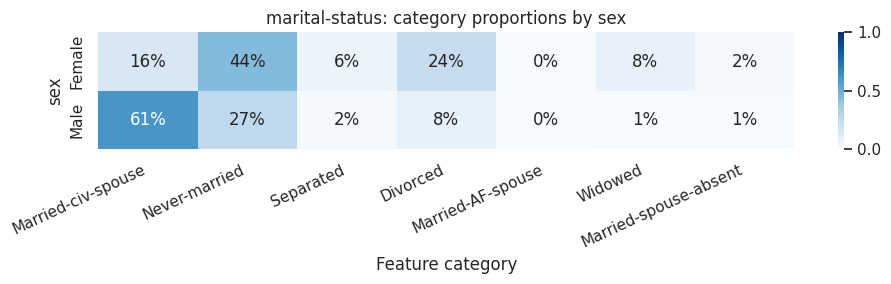

In [182]:
#| echo: false
plt.figure(figsize=(10, 3))
sns.heatmap(mf.by_group, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.title(f"{feature}: category proportions by sex")
plt.xlabel("Feature category")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# Data-Centric Audit Questions: Compare Group Coverage and Label Rates

Who is represented most often?

In [183]:
describe_by_group(adult_df, "sex", "income_gt_50k")


,count,share,positive_rate
sex,,,
Male,32650,0.668482,0.303767
Female,16192,0.331518,0.109251


In [184]:
describe_by_group(adult_df, "race", "income_gt_50k")

,count,share,positive_rate
race,,,
White,41762,0.855043,0.253987
Black,4685,0.095922,0.120811
Asian-Pac-Islander,1519,0.031100,0.269256
Amer-Indian-Eskimo,470,0.009623,0.117021
Other,406,0.008313,0.123153


# Fairness Through Unawareness: remove `sex` and `race`. Outcomes?

# Fairness Through Unawareness: remove `sex` and `race`

In [185]:
sex_train, sex_test = X_train_raw["sex"], X_test_raw["sex"]
race_train, race_test = X_train_raw["race"], X_test_raw["race"]
X_train = X_train_raw.drop(columns=["sex", "race"])
X_test = X_test_raw.drop(columns=["sex", "race"])  # Keep exactly the same test rows.
baseline = make_tabular_pipeline(X_train, depth=4)
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred_base), 3))


Balanced accuracy: 0.741


$Y=1$ means **observed income above 50K**, and $\hat{Y}=1$ means **predicted income above 50K**.

- **Selection rate:** among all people in a group, how many are predicted to earn above 50K?
- **True positive rate (TPR):** among people actually earning above 50K, how many does the model identify?
- **False negative rate (FNR):** among those same high-income people, how many does it miss? $\mathrm{FNR}=1-\mathrm{TPR}$.
- **False positive rate (FPR):** among people earning at most 50K, how many are incorrectly predicted above 50K?

# Data-Centric Audit Questions: Compare Group Coverage and Label Rates

In [186]:
def group_metrics(y_true, y_pred, groups):
    return MetricFrame(
        metrics={"accuracy": accuracy_score, "balanced_accuracy": balanced_accuracy_score, "selection_rate": selection_rate, "TP_rate": true_positive_rate, "FP_rate": false_positive_rate, "FN_rate": false_negative_rate},
        y_true=y_true, y_pred=y_pred, sensitive_features=groups,
    )
def model_summary(mf):
    gaps = mf.difference()  # Largest minus smallest group value for each metric.
    return {
        "accuracy": mf.overall["accuracy"], "balanced_accuracy": mf.overall["balanced_accuracy"], "balanced_accuracy_loss": 1 - mf.overall["balanced_accuracy"],
        "demographic_parity_diff": gaps["selection_rate"], "equal_opportunity_diff": gaps["TP_rate"], "equalized_odds_diff": gaps[["TP_rate", "FP_rate"]].max(),
    }
def fairness_report(y_true, y_pred, groups):
    mf = group_metrics(y_true, y_pred, groups)
    display(mf.overall.to_frame("overall").T.round(3), mf.by_group.round(3), pd.Series(model_summary(mf)).round(3))  # Reuse the same summary for every model.
    return mf
mf_sex_base = fairness_report(y_test, y_pred_base, sex_test)


,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
overall,0.844,0.741,0.178,0.545,0.062,0.455


,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
sex,,,,,,
Female,0.921,0.721,0.071,0.465,0.022,0.535
Male,0.805,0.736,0.232,0.559,0.088,0.441


,0
accuracy,0.844
balanced_accuracy,0.741
balanced_accuracy_loss,0.259
demographic_parity_diff,0.160
equal_opportunity_diff,0.094
equalized_odds_diff,0.094


# Interpreting the Baseline Audit

| Metric | Female | Male | Absolute gap |
|---|---:|---:|---:|
| Predicted above 50K (selection rate) | 7.1% | 23.2% | 16.0 percentage points |
| Identified among actual high earners (TPR) | 46.5% | 55.9% | 9.4 percentage points |
| Incorrectly positive among other earners (FPR) | 2.2% | 8.8% | 6.6 percentage points |

- **Statistical parity:** the model predicts high income more often for men; the selection-rate gap is **16.0 points**.
- **Equal opportunity:** of every 100 actual high earners in each group, it misses about **53 women versus 44 men**. The TPR gap is **9.4 points**.
- **Equalized odds:** compare both TPR and FPR; the reported gap is the larger of their gaps, **9.4 points**.
- **Accuracy alone can mislead:** accuracy is 92.1% for women versus 80.5% for men, yet recall of high-income women is lower.

The earlier proxy audit offers one possible explanation; these metrics do not identify the cause.

# Coding break 1: Exercises 1-2 (~15 minutes)

<a id="coding-break-1"></a>

Run the [setup](#coding-exercise-setup), then implement [Exercises 1-2](#coding-exercises-1).


# Intersectional Auditing

Auditing only one sensitive attribute can hide smaller groups. Fairlearn allows to audit intersections such as sex by race.

- Small groups can produce noisy estimates. When a subgroup has few examples, a large disparity may be real or random.
- Data-centric fixes may include collecting more data, improving subgroup coverage, or reporting uncertainty intervals.


In [187]:
intersection_test = pd.DataFrame({"sex": sex_test, "race": race_test})
mf_intersection = MetricFrame(
    metrics={"count": lambda yt, yp: len(yt), "accuracy": accuracy_score, "selection_rate": selection_rate, "FN_rate": false_negative_rate},
    y_true=y_test, y_pred=y_pred_base,
    sensitive_features=intersection_test,  # Evaluate every sex/race combination.
)
mf_intersection.by_group.sort_values("count", ascending=False)


count  accuracy  selection_rate   FN_rate
sex    race                                                          
Male   White               8571.0  0.798040        0.239529  0.440765
Female White               3953.0  0.916519        0.075386  0.533755
       Black                717.0  0.955370        0.043236  0.511111
Male   Black                716.0  0.868715        0.120112  0.530303
       Asian-Pac-Islander   292.0  0.767123        0.359589  0.305263
Female Asian-Pac-Islander   153.0  0.869281        0.111111  0.588235
Male   Amer-Indian-Eskimo    84.0  0.940476        0.059524  0.500000
       Other                 73.0  0.945205        0.068493  0.444444
Female Amer-Indian-Eskimo    62.0  0.919355        0.048387  0.666667
       Other                 32.0  0.937500        0.062500  0.500000

# Intersectional Fairness: Formulas

Let $G=(A_{\mathrm{sex}}, A_{\mathrm{race}})$ identify each intersectional group $g$. Apply the chosen criterion across **all intersections**, not separately to sex and race.

$$
\begin{aligned}
q_g &= P(\hat Y=1\mid G=g) &&\text{(selection rate)}\\
t_g &= P(\hat Y=1\mid Y=1,G=g) &&\text{(TPR)}\\
f_g &= P(\hat Y=1\mid Y=0,G=g) &&\text{(FPR)}
\end{aligned}
$$

For any group rate $r_g$, define $\Delta(r)=\max_g r_g-\min_g r_g$.

- **Statistical parity:** $\Delta(q)=0$.
- **Equal opportunity:** $\Delta(t)=0$ (equivalently, equal FNR since $\mathrm{FNR}_g=1-t_g$).
- **Equalized odds:** $\max\{\Delta(t),\Delta(f)\}=0$.

:::{.notes}
These are existing group fairness criteria applied to joint sensitive-attribute groups, rather than a single universal definition of intersectional fairness. Smaller gaps mean closer agreement with the chosen criterion; an approximate constraint can use a tolerance $\varepsilon$ instead of zero.

In the income example, $Y=1$ means income above 50K and $\hat Y=1$ means predicted income above 50K. Empirical rates are computed within each sex/race combination. Equal opportunity requires equal detection rates for actual high earners across those combinations.

Audits of sex and race separately can miss disparities at their intersections. Report subgroup counts and uncertainty; a conditional rate is undefined if its conditioning group has no observations (for example, TPR with no actual positives).

Source: [Fairlearn: Intersecting Groups](https://fairlearn.org/main/user_guide/assessment/intersecting_groups.html).
:::


# Intersectional Fairness: The Curse of Dimensionality

With $d$ sensitive attributes and $c_j$ categories per attribute, the number of possible intersections is:

$$K=\prod_{j=1}^{d}c_j \qquad (K=2^d\text{ if every attribute is binary}).$$

For $N=10{,}000$ audit observations, assuming evenly populated groups:

| Binary attributes $d$ | Possible groups $K$ | Observations per group $N/K$ |
|---|---:|---:|
| 2 | 4 | 2,500 |
| 5 | 32 | 312.5 |
| 10 | 1,024 | 9.8 |

- **Sparse evidence:** real groups are uneven; some intersections may be tiny or empty.
- **Unstable metrics:** TPR uses only actual positives, shrinking the denominator further; extreme gaps may reflect noise.
- **Audit response:** report counts and uncertainty, collect data for poorly covered groups, and flag estimates with insufficient support.

:::{.notes}
This is a statistical curse of dimensionality: increasing the number of attributes multiplies the number of intersectional groups while the audit sample remains fixed.

Inspecting more groups also creates more opportunities for extreme empirical gaps by chance. Account for multiple comparisons when making inferential claims. Wide uncertainty means that more evidence is needed; it does not establish either fairness or unfairness. Do not silently discard small groups or treat an empty group as having zero disparity.

Source: [Fairlearn: Confidence Interval Estimation](https://fairlearn.org/v0.12/user_guide/assessment/confidence_interval_estimation.html).
:::


# Part II. How do we *fix* fairness issues?

<a id="theory-block-2"></a>

First extend the group audit to intersections, then choose a purpose and an intervention.


# Before Mitigation: What Is the Purpose?

**Choosing a fairness criterion requires a purpose.**

- *What decision follows an income prediction?*
    - Should the goal be equal positive prediction rates, equal detection of high earners, or equal TPR and FPR?
- *Who is harmed by a false positive or false negative?*

**For a consistent comparison, we target equal opportunity:** identify the same fraction of actual high earners in each group.

# GDPR: Personal Data in a Fairness Audit {visibility="hidden"}

The **General Data Protection Regulation (EU) 2016/679** applies when processing personal data within its scope.

- **Arts. 5-6:** establish a lawful basis; respect fairness, transparency, purpose limitation, data minimisation, and accuracy.
- **Art. 9:** racial or ethnic origin and health data are special categories; processing requires an applicable exception as well as a lawful basis. Sex and age are not, by themselves, Art. 9 categories, although they can be protected attributes.
- **Art. 22:** restricts solely automated decisions with legal or similarly significant effects, subject to exceptions and safeguards; it does not prohibit every predictive score.
- **Art. 35:** a data protection impact assessment is required where processing is likely to create high risks to people's rights and freedoms.

Source: [GDPR, Arts. 5, 6, 9, 22, 35 (EUR-Lex)](https://eur-lex.europa.eu/eli/reg/2016/679/oj/eng).


# EU AI Act: From Fairness Metrics to System Duties {visibility="hidden"}

The **Artificial Intelligence Act, Regulation (EU) 2024/1689**, regulates AI systems according to their intended use and risk.

- **Art. 6 and Annex III:** specified uses in admissions, recruitment, and creditworthiness assessment are high-risk, subject to classification rules and exceptions.
- **Arts. 9-10:** high-risk requirements include risk management, data quality, examination of harmful biases, and mitigation. Subgroup audits support this work.
- **Arts. 13-14:** transparency to deployers and effective human oversight address how scores are interpreted and acted upon.
- **Art. 4a:** permits exceptional processing of special-category data for bias detection and correction under strict conditions and safeguards.

Source: [AI Act, consolidated 27 July 2026 (EUR-Lex)](https://eur-lex.europa.eu/eli/reg/2024/1689/2026-07-27/eng). Check **Art. 113** for phased application dates.


# Fairness Interventions: Where Do We Act?

| Stage | What changes? | Examples |
|---|---|---|
| **Pre-processing** | Training data or its representation | data augmentation, reweighting, feature transformations |
| **In-processing** | The learning procedure | fairness constraints, penalties, adversarial training |
| **Post-processing** | Decisions from an already trained model | group-specific thresholds, randomized decision rules |

# Fairlearn Tools by Intervention Stage

| Stage | Fairlearn tools | What they do |
|---|---|---|
| **Pre-processing** | `preprocessing.CorrelationRemover` | Reduce linear correlations between numeric features and sensitive attributes |
| **In-processing** | `reductions.ExponentiatedGradient` | Retrain a base estimator with adapted weights to seek a performance/fairness trade-off under a constraint |
| **Post-processing** | `postprocessing.ThresholdOptimizer` | Learn group-specific, possibly randomized thresholds over a model's scores |

Sources: [pre-processing](https://fairlearn.org/v0.9/user_guide/mitigation/preprocessing.html), [reductions](https://fairlearn.org/main/user_guide/mitigation/reductions.html), [adversarial mitigation](https://fairlearn.org/v0.12/user_guide/mitigation/adversarial.html), [post-processing](https://github.com/fairlearn/fairlearn/blob/main/docs/user_guide/mitigation/postprocessing.rst).


# [Pre-Processing]((https://fairlearn.org/v0.12/user_guide/mitigation/preprocessing.html)): Change the Data Before Training

- Removing correlation does not guarantee independence, statistical parity, or equal opportunity.
- Other data interventions include augmentation, reweighting, and better subgroup coverage.


In [188]:
def marital_proxy_input(X, sex):
    return pd.DataFrame({ "married": X["marital-status"].eq("Married-civ-spouse").astype(float), "is_male": sex.eq("Male").astype(float), })

proxy_train = marital_proxy_input(X_train, sex_train)
proxy_test = marital_proxy_input(X_test, sex_test)
remover = CorrelationRemover(sensitive_feature_ids=["is_male"], alpha=1)
married_train_corrected = remover.fit_transform(proxy_train)  # Learn only from training rows.
married_test_corrected = remover.transform(proxy_test)  # Apply the same correction to test rows.


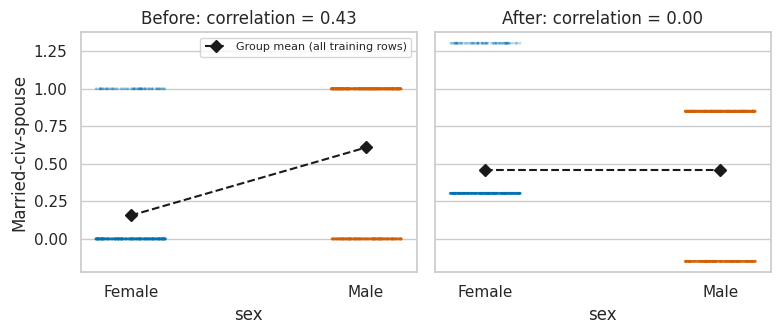

In [189]:
#| echo: false
#| fig-width: 10
#| fig-height: 4
proxy_values = pd.DataFrame({
    "Before": proxy_train["married"], "After": married_train_corrected[:, 0],
})
points = proxy_values.assign(sex=sex_train).sample(1600, random_state=RANDOM_STATE)
means = proxy_values.groupby(sex_train).mean().reindex(["Female", "Male"])
np.random.seed(RANDOM_STATE)  # Reproduce the display-only jitter.
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for ax, stage in zip(axes, ["Before", "After"]):
    sns.stripplot(data=points, x="sex", y=stage, hue="sex", order=["Female", "Male"],
                  palette=["#0072B2", "#D55E00"], jitter=0.15, alpha=0.25,
                  size=2, legend=False, ax=ax)  # Jitter separates overlapping points.
    ax.plot([0, 1], means[stage], "k--D", label="Group mean (all training rows)")
    correlation = proxy_values[stage].corr(proxy_train["is_male"])
    ax.set_title(f"{stage}: correlation = {correlation:.2f}")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("Married-civ-spouse")
plt.tight_layout()
plt.show()


#  [Pre-Processing]((https://fairlearn.org/v0.12/user_guide/mitigation/preprocessing.html)): Interpreting the Result

In [190]:
#| echo: false
def add_sex_indicator(X, sex):
    features = baseline["preprocess"].transform(X)
    if hasattr(features, "toarray"):
        features = features.toarray()  # CorrelationRemover needs a dense numeric array.
    return np.column_stack([sex.eq("Male").astype(float), features])


In [191]:
cr_X_train = add_sex_indicator(X_train, sex_train)
cr_X_test = add_sex_indicator(X_test, sex_test)
cr_tree_pipeline = Pipeline([
    ("remove_correlation", CorrelationRemover(sensitive_feature_ids=[0], alpha=1)),
    ("model", clone(baseline["model"])),  # A fresh tree with the baseline's settings.
])
cr_tree_pipeline.fit(cr_X_train, y_train)
y_pred_cr_tree = cr_tree_pipeline.predict(cr_X_test)


In [192]:
#| echo: false
mf_after = group_metrics(y_test, y_pred_cr_tree, sex_test)
display(pd.DataFrame({
    "Before": model_summary(mf_sex_base),
    "After": model_summary(mf_after),
}).T.round(3))


,accuracy,balanced_accuracy,balanced_accuracy_loss,demographic_parity_diff,equal_opportunity_diff,equalized_odds_diff
Before,0.844,0.741,0.259,0.160,0.094,0.094
After,0.844,0.734,0.266,0.145,0.068,0.068


Compare the **equal-opportunity gap** (`equal_opportunity_diff`); selection-rate and equalized-odds gaps are secondary diagnostics.

- **Interpretation:** reducing linear correlation does not explicitly optimize TPR parity. The tree can still use nonlinear group information.


# In-Processing: How ExponentiatedGradient Learns

The reductions method [@agarwal2018reductions] wraps our ordinary tree learner in an optimization loop: converts fairness requirements into a sequence of cost-sensitive learning problems

1. **Fit a candidate tree** using the current example costs/weights.
2. **Measure constraint violations:** check group TPR among training rows with $Y=1$.
3. **Update penalties:** exponentiated-gradient updates increase pressure on violated constraints, changing the costs for the next fit.
4. **Repeat and combine:** learn a weighted mixture of the candidate classifiers.

The result is a randomized mixture, not necessarily one tree.

# In-Processing: How [ExponentiatedGradient](https://fairlearn.org/v0.12/api_reference/generated/fairlearn.reductions.ExponentiatedGradient.html) Learns


In [193]:
reduction_eopp = ExponentiatedGradient(estimator=clone(baseline), constraints=TruePositiveRateParity(), eps=0.02, max_iter=25, sample_weight_name="model__sample_weight")
reduction_eopp.fit(X_train, y_train, sensitive_features=sex_train)
y_pred_reduction_eopp = reduction_eopp.predict(X_test, random_state=RANDOM_STATE)


In [194]:
#| echo: false
mf_reduction_eopp = fairness_report(y_test, y_pred_reduction_eopp, sex_test)

,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
overall,0.842,0.741,0.18,0.548,0.065,0.452


,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
sex,,,,,,
Female,0.918,0.744,0.087,0.520,0.033,0.480
Male,0.804,0.733,0.228,0.553,0.086,0.447


,0
accuracy,0.842
balanced_accuracy,0.741
balanced_accuracy_loss,0.259
demographic_parity_diff,0.141
equal_opportunity_diff,0.032
equalized_odds_diff,0.053


| Argument | Meaning |
|---|---|
| `estimator=clone(baseline)` | Retrain fresh copies of the same pipeline and depth-4 tree. |
| `constraints=TruePositiveRateParity()` | Balance TPR across sex groups among training rows with $Y=1$. See [constraint bounds](https://fairlearn.org/v0.12/user_guide/mitigation/reductions.html). |
| `eps=0.02` | Controls an internal optimization bound. |
| `max_iter=25` | Limit optimization rounds. |

# Coding break 2: Exercises 3-4 (~15 minutes)

<a id="coding-break-2"></a>

Go to [Exercises 3-4](#coding-exercises-2).


# Post-Processing: From Scores to Decisions

<a id="theory-block-3"></a>


Keep the fitted model fixed (its `predict_proba` output supplies a score $s(X)$ for income above 50K), change the rule that turns this score into a label:

$$\hat{Y}=\mathbf{1} \textup{ if } \{\hat{P}(Y = 1 | X) > thr_A\}, 0 \textup{ otherwise }$$

`ThresholdOptimizer` can choose a different threshold $t_A$ for each sex group.

| Hypothetical rule | Threshold | Decision for score 0.50 |
|---|---:|---|
| Women | 0.35 | Predict above 50K |
| Men | 0.60 | Predict at most 50K |

- Lowering a threshold produces more positive predictions and can increase both TPR and FPR.
- Raising it produces fewer positive predictions and can decrease both rates.
- The same score can lead to different decisions across groups; the chosen fairness objective determines the thresholds.

# How ThresholdOptimizer Chooses the Rule

*This is a new decision rule, not a refit of the tree*.

| `constraints` value | Rates to match |
|---|---|
| `"demographic_parity"` | Overall positive prediction rates |
| `"true_positive_rate_parity"` | TPR only: equal opportunity |
| `"equalized_odds"` | Both TPR and FPR |

Sources: [Fairlearn threshold algorithm](https://fairlearn.org/v0.12/user_guide/mitigation/postprocessing.html)


# How [ThresholdOptimizer](https://fairlearn.org/v0.12/api_reference/generated/fairlearn.postprocessing.ThresholdOptimizer.html) Chooses the Rule [@hardt2016equality]

In [195]:
threshold_eopp = ThresholdOptimizer(estimator=baseline, prefit=True, constraints="true_positive_rate_parity", objective="balanced_accuracy_score", predict_method="predict_proba",)
threshold_eopp.fit(X_train, y_train, sensitive_features=sex_train)
y_pred_threshold_eopp = threshold_eopp.predict(X_test, sensitive_features=sex_test, random_state=RANDOM_STATE,)  # Group-specific thresholds require sex at prediction time.

In [196]:
#| echo: false
mf_threshold_eopp = fairness_report(y_test, y_pred_threshold_eopp, sex_test)

,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
overall,0.768,0.785,0.383,0.816,0.247,0.184


,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
sex,,,,,,
Female,0.863,0.828,0.199,0.783,0.127,0.217
Male,0.720,0.749,0.476,0.822,0.324,0.178


,0
accuracy,0.768
balanced_accuracy,0.785
balanced_accuracy_loss,0.215
demographic_parity_diff,0.276
equal_opportunity_diff,0.039
equalized_odds_diff,0.197


| Argument | Meaning |
|---|---|
| `estimator=baseline, prefit=True` | Reuse the fitted tree and leave its parameters fixed. |
| `predict_method="predict_proba"` | Use the estimated probability of income above 50K as the score. |
| `constraints="true_positive_rate_parity"` | Seek equal TPR among actual high earners across sex groups. |
| `objective="balanced_accuracy_score"` | Maximize balanced accuracy subject to that constraint. |

# Recall: What Are We Equalizing?

In **Adult**, $Y=1$ means observed income above 50K; $\hat{Y}=1$ means predicted income above 50K.

**Equal opportunity** compares group TPRs: among actual high earners, what fraction does the model identify?

$$\mathrm{equal\_opportunity\_diff}=\max_a\mathrm{TPR}_a-\min_a\mathrm{TPR}_a.$$

- This is the common fairness measure for all five approaches.
- Statistical parity instead compares selection rates among **all** people.
- Equalized odds additionally checks FPR among people earning **at most 50K**.
- Equal opportunity alone does not require those other rates to match.


# Final comparison: five approaches

- **Raw pipeline:** original features, no fairness intervention.
- **Unawareness:** remove the sensitive predictor columns.
- **Pre-processing:** `CorrelationRemover` before the tree.
- **In-processing:** `ExponentiatedGradient` with equal opportunity (`TruePositiveRateParity`).
- **Post-processing:** `ThresholdOptimizer` with equal opportunity (`"true_positive_rate_parity"`).

Use **equal-opportunity gap** (lower is better) and **balanced accuracy** (higher is better) for every approach.

- The first three approaches do not enforce TPR parity.

In [197]:
#| echo: false
reports = {
    "Raw (no fairness)": group_metrics(y_test, y_pred_raw, sex_test),
    "Unawareness": mf_sex_base,
    "Pre-processing": mf_after,
    "In-processing": mf_reduction_eopp,
    "Post-processing": mf_threshold_eopp,
}
results = {}
for name, mf in reports.items():
    results[name] = model_summary(mf)  # Apply the same metrics to every approach.
comparison = pd.DataFrame(results).T.reset_index(names="model")  # One row per model.
display(comparison.round(3))


,model,accuracy,balanced_accuracy,balanced_accuracy_loss,demographic_parity_diff,equal_opportunity_diff,equalized_odds_diff
0,Raw (no fairness),0.844,0.741,0.259,0.160,0.094,0.094
1,Unawareness,0.844,0.741,0.259,0.160,0.094,0.094
2,Pre-processing,0.844,0.734,0.266,0.145,0.068,0.068
3,In-processing,0.842,0.741,0.259,0.141,0.032,0.053
4,Post-processing,0.768,0.785,0.215,0.276,0.039,0.197


# Fairness as a Multi-Objective Problem

![The skyline operator [@borzsony2001skyline]](./img/skyline.png)

# Fairness as a Multi-Objective Problem

We compare models using both balanced accuracy and fairness gaps: a **multi-objective optimization** problem.

> For a model $h$, we may want to:
>
> - *maximize utility*: $\operatorname{balanced\_accuracy}(h)$, profit, recall, or another task metric,
> - *minimize disparity*: equal-opportunity gap; other gaps remain diagnostics,
> - *satisfy constraints*: minimum subgroup sample size, maximum false negative gap, acceptable documentation quality.
>
> One compact formulation is $\max_h \left(\operatorname{utility}(h), -\operatorname{fairness\_gap}(h)\right)$
>
> - Subject to domain constraints such as $\operatorname{FNR\_gap}(h) \leq \delta$ and $\operatorname{support}(\mathrm{group}) \geq n_{\min}$.

| Strategy | What it does | Risk |
|---|---|---|
| Hard constraint | maximize accuracy subject to a fairness limit | the limit may be arbitrary |
| Scalarization | combine objectives, e.g. $\mathrm{score} = \mathrm{accuracy} - \lambda \cdot \mathrm{disparity}$ | hides value choices inside weights |
| Lexicographic rule | satisfy fairness first, then optimize accuracy | can discard useful trade-offs |
| Pareto frontier | keep all non-dominated candidates for review | still requires a human decision |

# Pareto Front: Equal Opportunity vs Predictive Performance

Compare the **five fitted approaches**, without training new models or sweeping thresholds.

- **Horizontal axis:** equal-opportunity gap (largest minus smallest group TPR).
- **Vertical axis:** balanced-accuracy loss, $1-\mathrm{balanced\_accuracy}$.
- Both quantities should be **minimized**: move toward the bottom-left corner.
- A solution is **dominated** if another is no worse on either axis and strictly better on at least one.
- The **Pareto front** contains the remaining solutions. Identical points do not dominate one another.


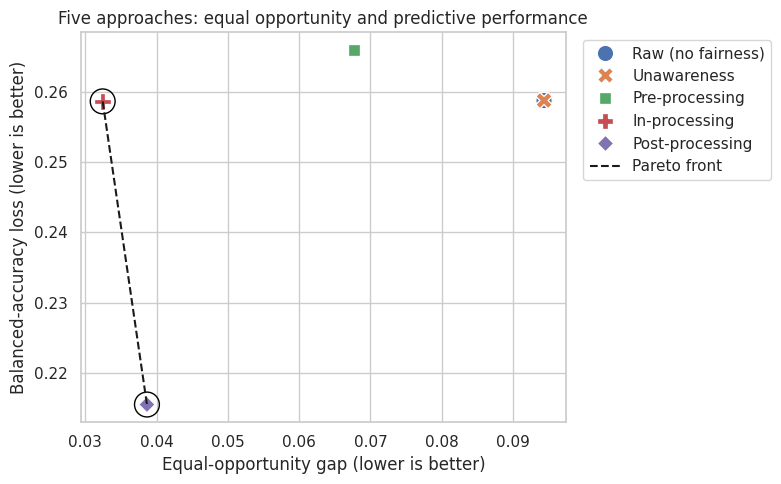

In [198]:
#| echo: false
def pareto_mask(gaps):
    keep = []
    for _, candidate in gaps.iterrows():
        no_worse = (gaps <= candidate).all(axis=1)  # No larger gap on either axis.
        better = (gaps < candidate).any(axis=1)  # Strictly smaller on at least one.
        keep.append(not (no_worse & better).any())
    return keep

x, y = "equal_opportunity_diff", "balanced_accuracy_loss"
comparison["pareto"] = pareto_mask(comparison[[x, y]])
front = comparison[comparison["pareto"]].sort_values(x)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=comparison, x=x, y=y, hue="model", style="model", s=140, ax=ax)
ax.plot(front[x], front[y], "k--", label="Pareto front")  # Connect the observed front points.
ax.scatter(front[x], front[y], s=320, facecolors="none", edgecolors="black")
ax.set(xlabel="Equal-opportunity gap (lower is better)",
       ylabel="Balanced-accuracy loss (lower is better)",
       title="Five approaches: equal opportunity and predictive performance")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# [Why Google's 'woke' AI problem won't be an easy fix](https://www.bbc.com/news/technology-68412620)

> Gemini also generated German soldiers from World War Two, incorrectly featuring a black man and Asian woman. [...] Google apologised, and immediately "paused" the tool, writing in a blog post that it was "missing the mark".

- **Task:** generate images of people from text prompts.
- **What happened:** in February 2024, Gemini generated inaccurate historical depictions and refused ordinary prompts.
    - Google said diversity tuning ignored contexts where a wider range of people was inappropriate.
- **Data-centric lesson:** assess representation, factual accuracy, prompt adherence, and refusal behavior together.

Source: [Google's explanation, 23 February 2024](https://blog.google/products-and-platforms/products/gemini/gemini-image-generation-issue/).



# Coding break 3: Exercises 5-6 (~15 minutes)

<a id="coding-break-3"></a>

Go to [Exercises 5-6](#coding-exercises-3).


# Practice: Fairlearn on Adult, Now Auditing Race

<a id="coding-exercise-setup"></a>


# Exercise 1: Inspect the Groups and Fit a Baseline

<a id="coding-exercises-1"></a>

Inspect race groups and fit an unaware baseline.

Which groups have few examples? Why does an income-rate difference alone not establish a model error?


In [199]:
# 1. Reuse X_train_raw, X_test_raw, y_train, and y_test; do not make a new split.
# 2. Keep race separately for auditing, then remove sex and race from the predictors.
# 3. Show training counts and observed high-income proportions for each race group.
# 4. Fit an unaware depth-4 tree and save its test predictions.

# Keep the protected attribute for auditing, separate from model inputs.
race_train, race_test = X_train_raw["race"], X_test_raw["race"]
display(race_train.value_counts())
display(pd.crosstab(race_train, y_train, normalize="index"))

X_race_train = X_train_raw.drop(columns=["sex", "race"])  # Remove sex and race.
X_race_test = X_test_raw.drop(columns=["sex", "race"])  # Remove the same columns.
race_baseline = make_tabular_pipeline(X_race_train, depth=4)
race_baseline.fit(X_race_train, y_train)  # Fit only on training predictors and labels.
pred_race_base = race_baseline.predict(X_race_test)


,count
race,
White,29238
Black,3252
Asian-Pac-Islander,1074
Amer-Indian-Eskimo,324
Other,301


income,0,1
race,,
Amer-Indian-Eskimo,0.873457,0.126543
Asian-Pac-Islander,0.723464,0.276536
Black,0.880381,0.119619
Other,0.870432,0.129568
White,0.746392,0.253608


# Exercise 2: Build and Read a MetricFrame

Audit the unaware baseline by race.

Which groups have the highest selection rate and missed-positive rate? Why do their denominators differ?


In [200]:
# 1. Create a MetricFrame for the unaware tree, grouping test predictions by race.
# 2. Inspect overall, by_group, and difference(). Use model_summary for the common summary.
# 3. Calculate the equal-opportunity gap (TPR gap).
# 4. Check the number of positive and negative test labels in each group before interpreting its error rates.

mf_race_base = MetricFrame(
    metrics={"accuracy": accuracy_score, "balanced_accuracy": balanced_accuracy_score,
             "selection_rate": selection_rate, "TP_rate": true_positive_rate,
             "FP_rate": false_positive_rate, "FN_rate": false_negative_rate},
    y_true=y_test, y_pred=pred_race_base, sensitive_features=race_test,  # Predictions and race_test.
)
display(mf_race_base.overall, mf_race_base.by_group)
gaps = mf_race_base.difference()
print("Equal-opportunity gap:", gaps["TP_rate"])  # Largest minus smallest TPR.
print("Selection gap:", gaps["selection_rate"])
print("Equalized-odds gap:", gaps[["TP_rate", "FP_rate"]].max())
display(pd.crosstab(race_test, y_test))  # Error-rate denominators can be small.
display(pd.Series(model_summary(mf_race_base)))


,0
accuracy,0.843650
balanced_accuracy,0.741216
selection_rate,0.177779
TP_rate,0.544780
FP_rate,0.062349
FN_rate,0.455220


,accuracy,balanced_accuracy,selection_rate,TP_rate,FP_rate,FN_rate
race,,,,,,
Amer-Indian-Eskimo,0.931507,0.706710,0.054795,0.428571,0.015152,0.571429
Asian-Pac-Islander,0.802247,0.752319,0.274157,0.651786,0.147147,0.348214
Black,0.912073,0.724151,0.081647,0.474576,0.026274,0.525424
Other,0.942857,0.767408,0.066667,0.545455,0.010638,0.454545
White,0.835436,0.740030,0.187720,0.545426,0.065366,0.454574


Equal-opportunity gap: 0.22321428571428575
Selection gap: 0.21936278282284133
Equalized-odds gap: 0.22321428571428575


income,0,1
race,,
Amer-Indian-Eskimo,132,14
Asian-Pac-Islander,333,112
Black,1256,177
Other,94,11
White,9332,3192


,0
accuracy,0.843650
balanced_accuracy,0.741216
balanced_accuracy_loss,0.258784
demographic_parity_diff,0.219363
equal_opportunity_diff,0.223214
equalized_odds_diff,0.223214


# Coding session 1 solution

<details>
<summary>Show the solution</summary>

```python
race_train, race_test = X_train_raw["race"], X_test_raw["race"]
display(race_train.value_counts())
display(pd.crosstab(race_train, y_train, normalize="index"))
X_race_train = X_train_raw.drop(columns=["sex", "race"])
X_race_test = X_test_raw.drop(columns=["sex", "race"])
race_baseline = make_tabular_pipeline(X_race_train, depth=4)
race_baseline.fit(X_race_train, y_train)
pred_race_base = race_baseline.predict(X_race_test)

mf_race_base = MetricFrame(
    metrics={"accuracy": accuracy_score, "balanced_accuracy": balanced_accuracy_score,
             "selection_rate": selection_rate, "TP_rate": true_positive_rate,
             "FP_rate": false_positive_rate, "FN_rate": false_negative_rate},
    y_true=y_test, y_pred=pred_race_base, sensitive_features=race_test,
)
display(mf_race_base.overall, mf_race_base.by_group)
gaps = mf_race_base.difference()
print("Equal-opportunity gap:", gaps["TP_rate"])
print("Selection gap:", gaps["selection_rate"])
print("Equalized-odds gap:", gaps[["TP_rate", "FP_rate"]].max())
display(pd.crosstab(race_test, y_test))
display(pd.Series(model_summary(mf_race_base)))
```

</details>


# Exercise 3: Pre-Processing with CorrelationRemover

<a id="coding-exercises-2"></a>

Compare correlation removal with the unaware baseline.

Does reducing linear correlation improve the held-out equal-opportunity gap?


In [201]:
# 1. One-hot encode race using training categories only. Do not assign ordinal numbers to race categories. Why?
# 2. Adapt the sex example: prepend all race indicator columns to the baseline's numeric predictors.
# 3. Pass their column positions to CorrelationRemover, then fit a fresh copy of the same tree.
# 4. Audit the new predictions by race and compare with Exercise 2.
# 5. Hint: if race has $k$ categories, the first $k$ columns are sensitive: list(range(k)).

race_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
race_encoder.fit(race_train.to_frame())  # Learn categories only from training rows.
k = len(race_encoder.categories_[0])

def add_race_indicators(X, groups):
    features = race_baseline["preprocess"].transform(X)
    if hasattr(features, "toarray"):
        features = features.toarray()
    indicators = race_encoder.transform(groups.to_frame())
    return np.column_stack([indicators, features])  # Race indicators come first.

race_pre = Pipeline([
    ("remove", CorrelationRemover(sensitive_feature_ids=list(range(k)), alpha=1)),
    ("model", clone(race_baseline["model"])),
])
race_pre.fit(add_race_indicators(X_race_train, race_train), y_train)
pred_race_pre = race_pre.predict(add_race_indicators(X_race_test, race_test))
mf_race_pre = group_metrics(y_test, pred_race_pre, race_test)



# Exercise 4: In-Processing with ExponentiatedGradient

Train an in-processing model for equal opportunity.

Did the TPR gap improve? What happened to balanced accuracy, FPR, and selection rates?


In [206]:
# 1. Start again from the unaware baseline, without applying Exercise 3's transformation.
# 2. Train ExponentiatedGradient using TruePositiveRateParity() and race_train.
# 3. Audit held-out predictions with group_metrics.

race_in = ExponentiatedGradient(
    estimator=clone(race_baseline),
    constraints=TruePositiveRateParity(),
    eps=0.02,
    max_iter=25,
    sample_weight_name="model__sample_weight",  # The pipeline's tree receives the weights.
)
race_in.fit(X_race_train, y_train, sensitive_features=race_train)
pred_race_in = race_in.predict(X_race_test, random_state=RANDOM_STATE)
mf_race_in = group_metrics(y_test, pred_race_in, race_test)

# Code hint: compare model_summary(mf_race_base) with model_summary(mf_race_in).
display(pd.DataFrame({
    "Unawareness": model_summary(mf_race_base),
    "Pre-processing": model_summary(mf_race_pre),
    "In-processing": model_summary(mf_race_in),
}).T.round(3))

,accuracy,balanced_accuracy,balanced_accuracy_loss,demographic_parity_diff,equal_opportunity_diff,equalized_odds_diff
Unawareness,0.844,0.741,0.259,0.219,0.223,0.223
Pre-processing,0.844,0.740,0.260,0.201,0.188,0.188
In-processing,0.827,0.694,0.306,0.107,0.208,0.208


# Coding session 2 solution

<details>
<summary>Show the solution</summary>

```python
race_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
race_encoder.fit(race_train.to_frame())
k = len(race_encoder.categories_[0])

def add_race_indicators(X, groups):
    features = race_baseline["preprocess"].transform(X)
    if hasattr(features, "toarray"):
        features = features.toarray()
    indicators = race_encoder.transform(groups.to_frame())
    return np.column_stack([indicators, features])

race_pre = Pipeline([
    ("remove", CorrelationRemover(sensitive_feature_ids=list(range(k)), alpha=1)),
    ("model", clone(race_baseline["model"])),
])
race_pre.fit(add_race_indicators(X_race_train, race_train), y_train)
pred_race_pre = race_pre.predict(add_race_indicators(X_race_test, race_test))
mf_race_pre = group_metrics(y_test, pred_race_pre, race_test)

race_in = ExponentiatedGradient(
    estimator=clone(race_baseline), constraints=TruePositiveRateParity(),
    eps=0.02, max_iter=25, sample_weight_name="model__sample_weight",
)
race_in.fit(X_race_train, y_train, sensitive_features=race_train)
pred_race_in = race_in.predict(X_race_test, random_state=RANDOM_STATE)
mf_race_in = group_metrics(y_test, pred_race_in, race_test)
display(pd.DataFrame({
    "Unawareness": model_summary(mf_race_base),
    "Pre-processing": model_summary(mf_race_pre),
    "In-processing": model_summary(mf_race_in),
}).T.round(3))
```

</details>


# Exercise 5: Post-Processing with ThresholdOptimizer

<a id="coding-exercises-3"></a>

Learn a post-processing rule for equal opportunity.

Can improving TPR parity worsen other gaps? Why is prefit=True appropriate here?


In [207]:
# 1. Keep Exercise 1's fitted unaware baseline and learn a new decision rule for equal opportunity.
# 2. Supply race during both fit and predict.
# 3. Audit the result; compare its TPR gap, balanced accuracy, and diagnostic gaps with the previous approaches.

race_post = ThresholdOptimizer(
    estimator=race_baseline, prefit=True,  # Keep the fitted baseline tree.
    constraints="true_positive_rate_parity", objective="balanced_accuracy_score",  # Use "true_positive_rate_parity".
    predict_method="predict_proba",
)
race_post.fit(X_race_train, y_train, sensitive_features=race_train)  # Use training race values.
pred_race_post = race_post.predict(
    X_race_test, sensitive_features=race_test, random_state=RANDOM_STATE,
)  # Use test race values; do not use test labels to learn thresholds.
mf_race_post = group_metrics(y_test, pred_race_post, race_test)


# Exercise 6: Compare Five Approaches and Explain

Compare five approaches on fairness and predictive performance.

What changed from the sex audit? Which small-group estimates need caution, and why does the Pareto front not decide fairness?


,model,accuracy,balanced_accuracy,balanced_accuracy_loss,demographic_parity_diff,equal_opportunity_diff,equalized_odds_diff
0,Raw (no fairness),0.844,0.741,0.259,0.219,0.223,0.223
1,Unawareness,0.844,0.741,0.259,0.219,0.223,0.223
2,Pre-processing,0.844,0.740,0.260,0.201,0.188,0.188
3,In-processing,0.827,0.694,0.306,0.107,0.208,0.208
4,Post-processing,0.758,0.802,0.198,0.289,0.182,0.219


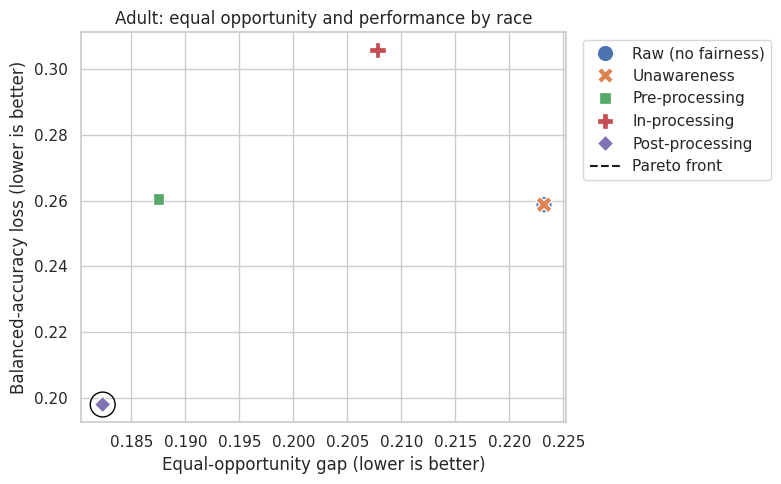

In [208]:
# 1. Compare raw, unaware, pre-processed, in-processed, and post-processed predictions by race, on the same test rows.
# 2. Build a table with model_summary; plot equal-opportunity gap against balanced-accuracy loss (1 - balanced_accuracy).
# 3. Reuse pareto_mask to highlight the non-dominated models; both plotted quantities should be minimized.
# 4. Recommend one approach using the common equal-opportunity target and balanced accuracy; inspect the other gaps as diagnostics.

race_reports = {
    "Raw (no fairness)": group_metrics(y_test, y_pred_raw, race_test),
    "Unawareness": mf_race_base,
    "Pre-processing": mf_race_pre,
    "In-processing": mf_race_in,
    "Post-processing": mf_race_post,
}

race_results = {}
for name, report in race_reports.items():
    race_results[name] = model_summary(report)
# Same as `race_results = {name: model_summary(report) for name, report in race_reports.items()}`

race_comparison = pd.DataFrame(race_results).T.reset_index(names="model")
display(race_comparison.round(3))

x, y = "equal_opportunity_diff", "balanced_accuracy_loss"
race_comparison["pareto"] = pareto_mask(race_comparison[[x, y]])
front_race = race_comparison[race_comparison["pareto"]].sort_values(x)
# Hint: copy the five-model scatter plot and replace comparison/front with these objects.
# Label both axes "lower is better"; use equal-opportunity gap and balanced-accuracy loss.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=race_comparison, x=x, y=y, hue="model", style="model", s=140, ax=ax)
ax.plot(front_race[x], front_race[y], "k--", label="Pareto front")
ax.scatter(front_race[x], front_race[y], s=320, facecolors="none", edgecolors="black")
ax.set(xlabel="Equal-opportunity gap (lower is better)",
       ylabel="Balanced-accuracy loss (lower is better)",
       title="Adult: equal opportunity and performance by race")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Closing Questions

- Which groups are missing or poorly represented in this dataset?
- Which point on the multi-objective frontier is acceptable for this domain, and who gets to decide?


# Coding session 3 solution

<details>
<summary>Show the solution</summary>

```python
race_post = ThresholdOptimizer(
    estimator=race_baseline, prefit=True,
    constraints="true_positive_rate_parity", objective="balanced_accuracy_score",
    predict_method="predict_proba",
)
race_post.fit(X_race_train, y_train, sensitive_features=race_train)
pred_race_post = race_post.predict(
    X_race_test, sensitive_features=race_test, random_state=RANDOM_STATE,
)
mf_race_post = group_metrics(y_test, pred_race_post, race_test)

race_reports = {
    "Raw (no fairness)": group_metrics(y_test, y_pred_raw, race_test),
    "Unawareness": mf_race_base,
    "Pre-processing": mf_race_pre,
    "In-processing": mf_race_in,
    "Post-processing": mf_race_post,
}
race_comparison = pd.DataFrame({
    name: model_summary(report) for name, report in race_reports.items()
}).T.reset_index(names="model")
display(race_comparison.round(3))
x, y = "equal_opportunity_diff", "balanced_accuracy_loss"
race_comparison["pareto"] = pareto_mask(race_comparison[[x, y]])
front_race = race_comparison[race_comparison["pareto"]].sort_values(x)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=race_comparison, x=x, y=y, hue="model", style="model", s=140, ax=ax)
ax.plot(front_race[x], front_race[y], "k--", label="Pareto front")
ax.scatter(front_race[x], front_race[y], s=320, facecolors="none", edgecolors="black")
ax.set(xlabel="Equal-opportunity gap (lower is better)",
       ylabel="Balanced-accuracy loss (lower is better)",
       title="Adult: equal opportunity and performance by race")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
```

</details>


# Further Reading

- Bias and fairness: [@chenBiasFairness; @cse312fairness].
- Toolkit documentation: [@fairlearnDocumentation].
- Fair prediction and individual fairness: [@chouldechova2017fair; @dwork2012fairness].
- Learning fair representations: [@zemel2013learning].

- EU regulations: [GDPR (EU) 2016/679](https://eur-lex.europa.eu/eli/reg/2016/679/oj/eng); [AI Act (EU) 2024/1689, consolidated text](https://eur-lex.europa.eu/eli/reg/2024/1689/2026-07-27/eng).

# References

::: {#refs}
:::
